# Обнаружение объектов

Импортируем необходимые модули

In [ ]:
from PIL import Image

import cv2

import numpy as np

import torch
import torchvision
import torchvision.transforms as T

from torch.utils.data import DataLoader, Dataset

import pandas as pd

import os

import matplotlib.pyplot as plt

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 7.1 MB/s eta 0:00:00


Определяем, где находятся изображения с рамками

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Создаем датасет, который возвращает картинку и боксы.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random

def draw_yolo_boxes(image_path, label_path, class_names=None, color=(255, 0, 0), thickness=2):
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(f"Не найдено: {image_path}")

    h, w = img.shape[:2]

    if Path(label_path).exists():
        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            if len(parts) < 5:
                continue

            cls_id = int(parts[0])
            x_c, y_c, bw, bh = map(float, parts[1:5])

            # Денормализация в пиксели
            x1 = int((x_c - bw / 2) * w)
            y1 = int((y_c - bh / 2) * h)
            x2 = int((x_c + bw / 2) * w)
            y2 = int((y_c + bh / 2) * h)

            # Рисуем рамку
            cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)

            # Подпись класса
            if class_names is not None and cls_id < len(class_names):
                label = class_names[cls_id]
                # Фон под текстом
                (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
                cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw + 4, y1), color, -1)
                cv2.putText(img, label, (x1 + 2, y1 - 4),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)

    # BGR -> RGB для matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img_rgb




In [ ]:
def show_random_samples(images_dir, labels_dir, class_names=None, n=4, seed=42):
    images_dir = Path(images_dir)
    labels_dir = Path(labels_dir)

    image_files = list(images_dir.glob("*.jpg")) + list(images_dir.glob("*.png")) + list(images_dir.glob("*.jpeg"))

    if len(image_files) == 0:
        print(f"Не найдено картинок в {images_dir}")
        return

    random.seed(seed)
    samples = random.sample(image_files, min(n, len(image_files)))

    fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 5))
    if len(samples) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, samples):
        label_path = labels_dir / (img_path.stem + ".txt")
        img_rgb = draw_yolo_boxes(img_path, label_path, class_names=class_names)
        ax.imshow(img_rgb)
        ax.set_title(img_path.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Создадим датасет

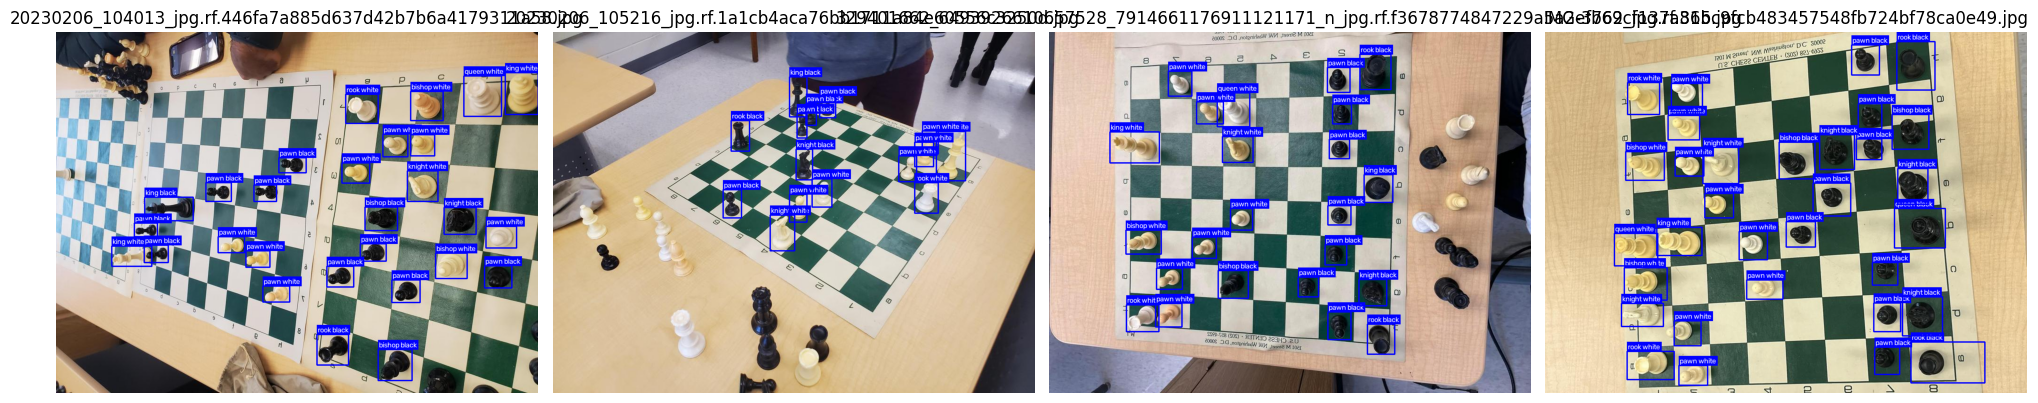

In [ ]:
class_names = ['bishop black', 'bishop white', 'king black', 'king white', 'knight black', 'knight white',
               'pawn black', 'pawn white', 'queen black', 'queen white', 'rook black', 'rook white']

show_random_samples(
    images_dir="/content/drive/MyDrive/Colab Notebooks/data1/train/images",
    labels_dir="/content/drive/MyDrive/Colab Notebooks/data1/train/labels",
    class_names=class_names,
    n=4
)

Создадим модель на 12 классов на базе Yolov8n

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
print(model)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_s

In [ ]:
import os

yaml_content = """path: /content/drive/MyDrive/Colab Notebooks/data1
train: train/images
val: valid/images

nc: 12
names:
  0: black_bishop
  1: white_bishop
  2: black_king
  3: white_king
  4: black_knight
  5: white_knight
  6: black_pawn
  7: white_pawn
  8: black_queen
  9: white_queen
  10: black_rook
  11: white_rook
"""

yaml_path = "/content/drive/MyDrive/Colab Notebooks/chess.yaml"
with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("OK, файл создан")
print(open(yaml_path, encoding="utf-8").read())

OK, файл создан
path: /content/drive/MyDrive/Colab Notebooks/data1
train: train/images
val: valid/images

nc: 12
names:
  0: black_bishop
  1: white_bishop
  2: black_king
  3: white_king
  4: black_knight
  5: white_knight
  6: black_pawn
  7: white_pawn
  8: black_queen
  9: white_queen
  10: black_rook
  11: white_rook



In [ ]:
results = model.train(
    data="/content/drive/MyDrive/Colab Notebooks/chess.yaml",
    epochs=100,
    imgsz=640,
    batch=32,
    freeze=4
)

Ultralytics 8.4.160 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Colab Notebooks/chess.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=4, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na


image 1/83 /content/drive/MyDrive/Colab Notebooks/data1/test/images/0DE76AED-2C88-41CA-B8BD-22717CA168C8_jpeg.rf.65683b8aa73a07642357653bbf5f31ca.jpg: 480x640 1 black_bishop, 1 white_bishop, 2 black_kings, 1 black_knight, 1 white_knight, 6 black_pawns, 8 white_pawns, 2 black_rooks, 6.2ms
image 2/83 /content/drive/MyDrive/Colab Notebooks/data1/test/images/123FBAB3-A30C-46FF-AB8D-6DE4967D8583_jpeg.rf.92078a9cad1681c2fe446fc02cdc47bf.jpg: 480x640 4 white_bishops, 1 black_knight, 4 black_pawns, 6 white_pawns, 1 black_rook, 1 white_rook, 6.6ms
image 3/83 /content/drive/MyDrive/Colab Notebooks/data1/test/images/20230131_114345_jpg.rf.3900ccd7fd42c21721f22e9f715ba8e6.jpg: 480x640 1 black_bishop, 1 white_king, 4 black_pawns, 3 white_pawns, 1 white_rook, 6.7ms
image 4/83 /content/drive/MyDrive/Colab Notebooks/data1/test/images/20230206_103709_jpg.rf.311e2900c718c5b8f9572b0ccc672c54.jpg: 480x640 1 black_bishop, 1 white_king, 6 black_pawns, 9 white_pawns, 2 white_rooks, 6.4ms
image 5/83 /content

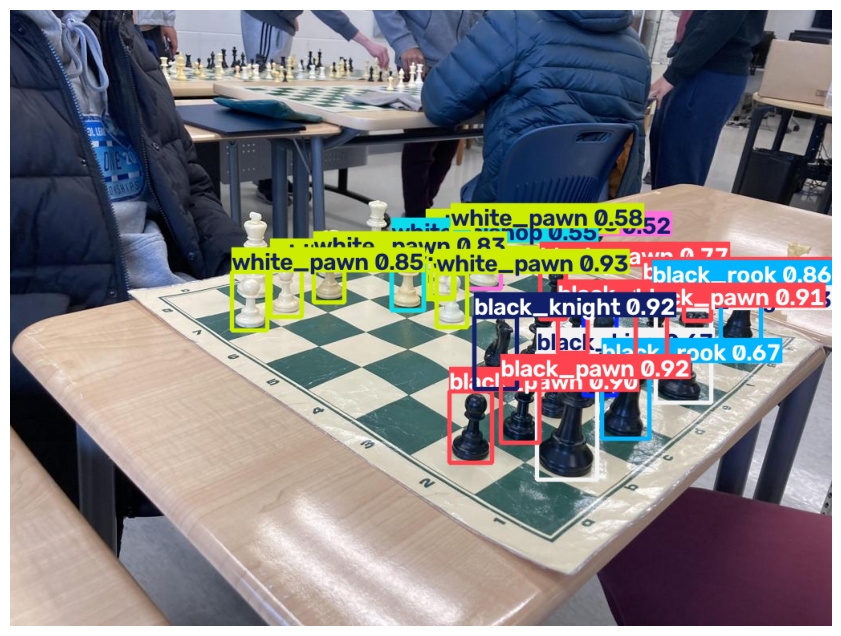

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

model = YOLO("/content/runs/detect/train/weights/best.pt")

source_dir = "/content/drive/MyDrive/Colab Notebooks/data1/test/images"
results = model.predict(source=source_dir, conf=0.5, save=True)

r = results[0]
for box in r.boxes:
    cls_id = int(box.cls)
    conf = float(box.conf)
    print(f"  {model.names[cls_id]}: {conf:.2f}")

plt.figure(figsize=(12, 8))
plt.imshow(r.plot()[..., ::-1])
plt.axis("off")
plt.show()